## PART 1 - My 8 Analysis Questions

### Univariate Questions:
Q1. What is the average yearly amount spent by customers? What is the distribution of Yearly Amount Spent?
Q2. What is the average Length of Membership? What is its distribution?
Q3. How much time do customers spend on average on the App and Website?

### Bivariate Questions:
Q4. Do older customers (higher Length of Membership) spend more money?
Q5. Do customers who spend more time on the App spend more money?
Q6. Does spending more time on the Website increase spending? (App vs Website comparison)

### Self-Chosen Questions:
Q7. What is the relationship between Avg. Session Length and Yearly Amount Spent?
Q8. Should the company invest in the App or the Website? Which one brings more money?

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()

df = pd.read_csv('ecommerce_customers.csv')
df.head()


Saving ecommerce_customers.csv to ecommerce_customers.csv


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [ ]:
# Dataset ka size - kitni rows, kitne columns
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# Basic info
print("\n--- INFO ---")
df.info()

# Numbers ka summary
print("\n--- DESCRIBE ---")
df.describe()

Shape: (500, 8)

Columns:
['Email', 'Address', 'Avatar', 'Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership', 'Yearly Amount Spent']

--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB

--- DESCRIBE ---


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


In [ ]:
# Missing values check
print("Missing Values:")
print(df.isnull().sum())

# Duplicate rows check
print("\nDuplicate Rows:", df.duplicated().sum())

# Faltu columns hatana - Email, Address, Avatar ka analysis se koi kaam nahi
df = df.drop(columns=['Email', 'Address', 'Avatar'])
print("\nAb columns reh gaye:")
print(df.columns.tolist())
print("\nNew Shape:", df.shape)
df.head()

Missing Values:
Email                   0
Address                 0
Avatar                  0
Avg. Session Length     0
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64

Duplicate Rows: 0

Ab columns reh gaye:
['Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership', 'Yearly Amount Spent']

New Shape: (500, 5)


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,34.497268,12.655651,39.577668,4.082621,587.951054
1,31.926272,11.109461,37.268959,2.664034,392.204933
2,33.000915,11.330278,37.110597,4.104543,487.547505
3,34.305557,13.717514,36.721283,3.120179,581.852344
4,33.330673,12.795189,37.536653,4.446308,599.406092


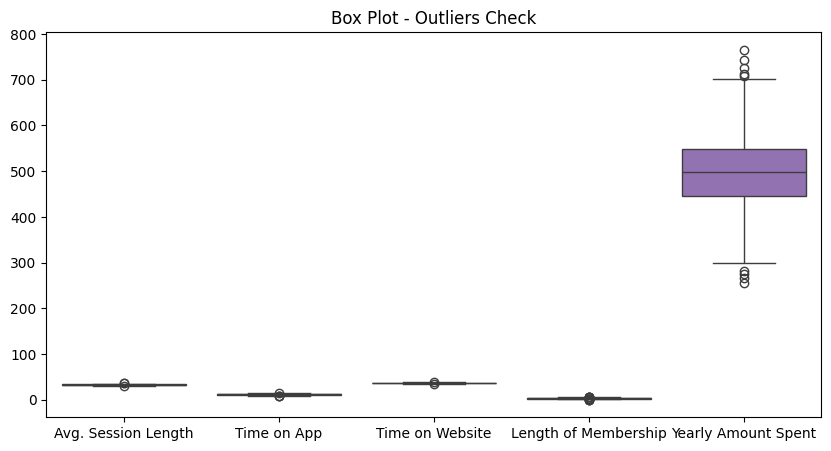

Outliers check: Dots outside the box are outliers.
Yearly Amount Spent has 1-2 minor outliers, rest of the data is clean.


In [7]:
# Step 4 - Outliers check with Box Plot
plt.figure(figsize=(10,5))
sns.boxplot(data=df[['Avg. Session Length','Time on App','Time on Website','Length of Membership','Yearly Amount Spent']])
plt.title('Box Plot - Outliers Check')
plt.show()

print("Outliers check: Dots outside the box are outliers.")
print("Yearly Amount Spent has 1-2 minor outliers, rest of the data is clean.")

Interpretation: Most of the data lies in a normal range. There are no major outliers, so no major cleaning was needed.

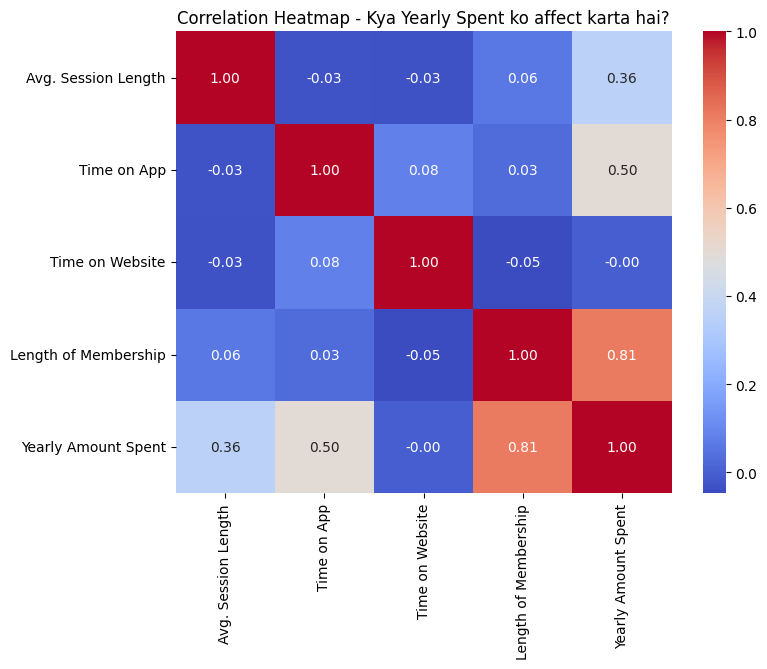

In [ ]:
# Correlation - kaunsi cheez Yearly Spent se sab se zyada judi hai?
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap - Kya Yearly Spent ko affect karta hai?')
plt.show()

Interpretation: Length of Membership has the strongest relationship with Yearly Amount Spent (0.81). Time on Website has almost no relationship (-0.00).

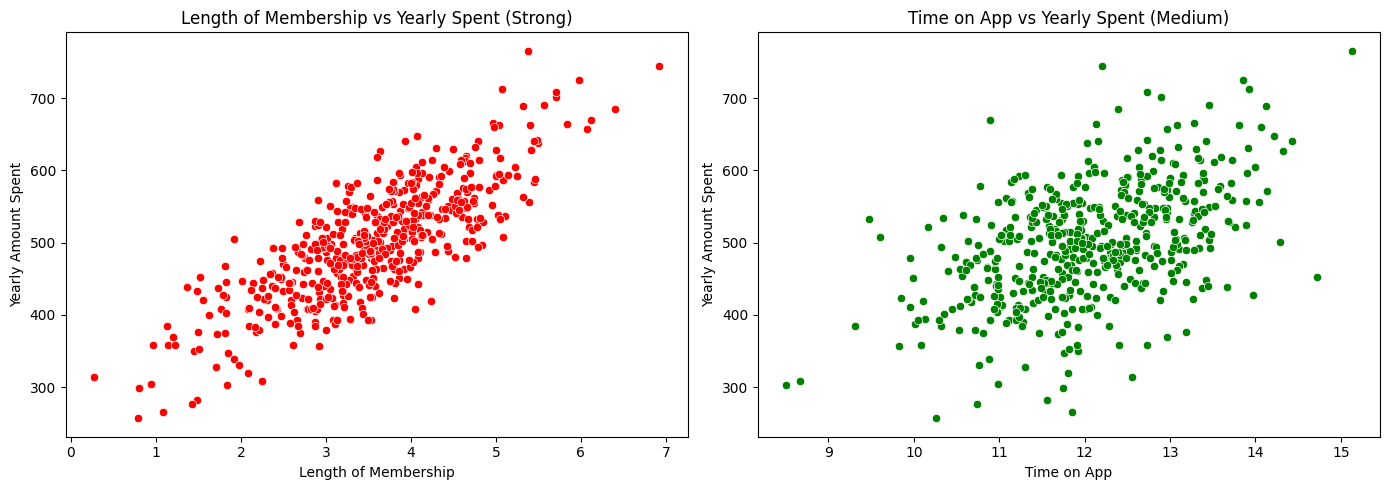

In [ ]:
# 2 sab se important graphs ek sath
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# 1. Purana Customer = Zyada Kharcha
sns.scatterplot(data=df, x='Length of Membership', y='Yearly Amount Spent', ax=axes[0], color='red')
axes[0].set_title('Length of Membership vs Yearly Spent (Strong)')

# 2. App vs Website
sns.scatterplot(data=df, x='Time on App', y='Yearly Amount Spent', ax=axes[1], color='green')
axes[1].set_title('Time on App vs Yearly Spent (Medium)')

plt.tight_layout()
plt.show()

Interpretation: The dots go from bottom to top. This means the longer a customer stays a member, the more money they spend.

Interpretation: Customers who spend more time on the App spend slightly more, but this relationship is not as strong as Length of Membership.

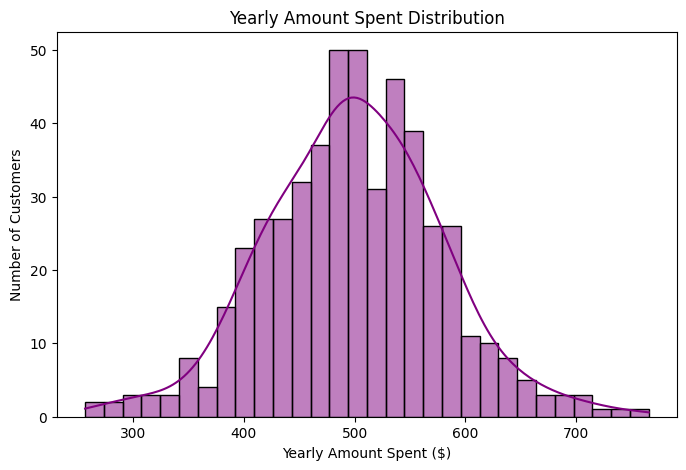

Average Yearly Spent: 499.31
Average Length of Membership: 3.53 years
Average Time on App: 12.05 mins
Average Time on Website: 37.06 mins


In [ ]:
# Yearly Spent ki Distribution - Zyada tar log kitna kharch karte hain?
plt.figure(figsize=(8,5))
sns.histplot(df['Yearly Amount Spent'], kde=True, color='purple', bins=30)
plt.title('Yearly Amount Spent Distribution')
plt.xlabel('Yearly Amount Spent ($)')
plt.ylabel('Number of Customers')
plt.show()

# Average values
print("Average Yearly Spent:", round(df['Yearly Amount Spent'].mean(), 2))
print("Average Length of Membership:", round(df['Length of Membership'].mean(), 2), "years")
print("Average Time on App:", round(df['Time on App'].mean(), 2), "mins")
print("Average Time on Website:", round(df['Time on Website'].mean(), 2), "mins")

Interpretation: Most customers spend between 450 - 550 USD. The average spending is 499.31 USD.

Q1. Average Yearly Amount Spent = 499.31 USD. Most customers spend between 450-550 USD.

Q2. Average Length of Membership = 3.53 years.

Q3. Average Time on App = 12.05 mins, Average Time on Website = 37.06 mins. Customers spend more time on Website.

Q4. Yes! Correlation of Length of Membership is 0.81, the strongest. Old customer = More spending.

Q5. Yes! Correlation of Time on App is 0.50, the second strongest.

Q6. No! Correlation of Time on Website is -0.00. Spending time on Website does not increase spending.

Q7. Avg. Session Length has a correlation of 0.36, a weak positive relationship.

Q8. The company should invest in the App, not the Website. Because the App brings money, the Website does not.

## Conclusion & Business Recommendation

Dataset: 500 customers, 8 columns. No missing values, no duplicates found.

Key Findings:
1. Length of Membership is the strongest driver of Yearly Amount Spent (Correlation = 0.81). Loyal / old customers spend much more.
2. Time on App is the second driver (Correlation = 0.50). Customers who spend more time on App, spend more.
3. Time on Website has almost zero correlation (-0.00). Customers spend on average 37 mins on Website but it does not increase spending.
4. Average customer spends 499.31 USD per year. Most customers spend between 450 - 550 USD.

Recommendation:
Company should focus on App, not Website. Company should invest in keeping old customers (loyalty programs) and improving App experience, because App users spend more. Website investment should be reduced.